<a href="https://colab.research.google.com/github/luiflower17-ui/IA/blob/main/T3_Spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Carga de datos Spotify

In [10]:
import pandas as pd

url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)

### Visualización del Dataframe

In [11]:
df

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


### Selección de características

In [12]:
# Seleccionar características (features)
features = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'duration_ms',
]
X = df[features].values

# Target numérico
y = df['popularity'].values

### División de datos

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, random_state=42
)

### Escalado de características

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Creación del modelo

In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Configuración del optimizador

In [16]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.001
adam_optimizer = Adam(learning_rate=learning_rate)

### Compilación del modelo

In [17]:
model.compile(
    optimizer=adam_optimizer,
    loss='mse',
    metrics=['mae'],
)

### Entrenamiento del modelo

In [18]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=50,
)

Epoch 1/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 569.1148 - mae: 19.5699 - val_loss: 486.2418 - val_mae: 18.2144
Epoch 2/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 481.3727 - mae: 18.1439 - val_loss: 480.0694 - val_mae: 17.9761
Epoch 3/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 472.3714 - mae: 17.9144 - val_loss: 469.1507 - val_mae: 17.7949
Epoch 4/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 466.0106 - mae: 17.7441 - val_loss: 463.7651 - val_mae: 17.6795
Epoch 5/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 462.2557 - mae: 17.6472 - val_loss: 461.7489 - val_mae: 17.5820
Epoch 6/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 459.5604 - mae: 17.5721 - val_loss: 459.4972 - val_mae: 17.4876
Epoch 7/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 457.4907 - mae: 17.5197 - val_loss: 459.5145 - val_mae: 17.4616
Epoch 8/50
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 455.7833 - mae: 17.4706 - val_loss: 457.7784 - val_mae: 

### Gráfica de pérdida

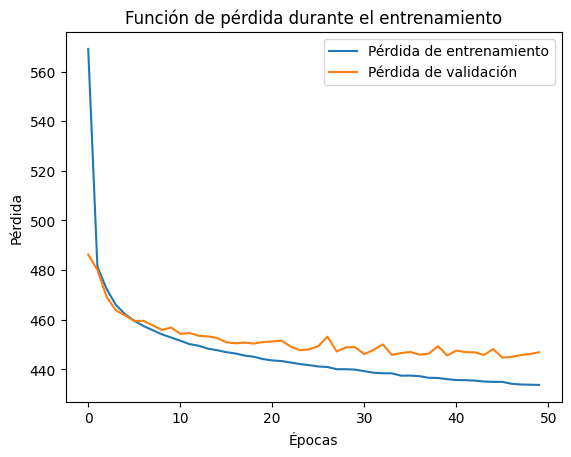

In [19]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()

### Se evalúa el modelo

In [20]:
loss, mae = model.evaluate(X_test, y_test)
print(f"MAE en el conjunto test: {mae}")

713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 442.7339 - mae: 17.0890
MAE en el conjunto test: 17.08903694152832


### Predicciones versus sus valores reales

In [21]:
import pandas as pd

predictions = model.predict(X_test)
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': predictions.flatten()})
print(comparison.head())

713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
   Actual  Predicted
0      50  42.310680
1      11  17.692652
2       0  28.740257
3       0  34.891304
4      57  33.736221


### Búsqueda de canciones

In [22]:
nombre_cancion = "Beso"

canciones_df = df[df['track_name'].str.contains(nombre_cancion, case=False, na=False)]

print(f"Canciones encontradas:")
canciones_df[['track_name', 'artists', 'album_name']].head()

Canciones encontradas:


,track_name,artists,album_name
1655,Un Beso de Desayuno,Calle 13,Residente o Visitante
17425,Beso Con Baba,Meth Math;Dinamarca,m♡rtal
21293,Son Tus Besos,Cestar,El Verdadero Amor
23145,El Beso (feat. Mathieu Ruz),Dombresky;Crusy,Toolroom Amsterdam 2022
23927,El Beso (feat. Mathieu Ruz),Dombresky;Crusy,El Beso (feat. Mathieu Ruz)


### Predicción de canción

In [23]:
# indice a selecionar
i = 0
cancion = canciones_df.iloc[i]
X_input = cancion[features].values.reshape(1, -1)
X_input = scaler.transform(X_input)

prediccion = model.predict(X_input)[0][0]
print(f"Canción: {cancion['track_name']} - {cancion['artists']}")
print(f"Popularidad real: {cancion['popularity']}")
print(f"Predicción: {prediccion:.2f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Canción: Un Beso de Desayuno - Calle 13
Popularidad real: 20
Predicción: 41.26


### Cálculo de métricas finales

In [24]:
from sklearn.metrics import r2_score, mean_squared_error

r2 = r2_score(y_test, predictions)
print(f'R²: {r2}')

mse = mean_squared_error(y_test, predictions)
print(f'MSE: {mse}')

R²: 0.10283458232879639
MSE: 442.7339782714844


### Clasificación de Género Musical en Spotify

En esta sección, prepararemos los datos para clasificar las canciones en sus respectivos géneros musicales, entrenaremos una red neuronal optimizada y evaluaremos su exactitud.

In [25]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np

# Aseguramos la carga del dataset en la variable df si no está presente
try:
    _ = df.shape
except NameError:
    url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
    df = pd.read_csv(url)

# 1. Preparación de variables de entrada (X) y objetivo (y)
features_genre = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'duration_ms'
]

X_genre = df[features_genre].values

# Codificamos la variable categórica 'track_genre'
label_encoder = LabelEncoder()
y_genre = label_encoder.fit_transform(df['track_genre'])
num_classes = len(label_encoder.classes_)

print(f"Número de géneros únicos a clasificar: {num_classes}")

Número de géneros únicos a clasificar: 114


In [26]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping

# 1. Asegurar la carga de datos y preparación
try:
    _ = df.shape
except NameError:
    url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
    df = pd.read_csv(url)

features_genre = [
    'danceability', 'energy', 'key', 'loudness',
    'mode', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'duration_ms'
]

X_genre = df[features_genre].values
label_encoder = LabelEncoder()
y_genre = label_encoder.fit_transform(df['track_genre'])
num_classes = len(label_encoder.classes_)

# 2. División de datos (Estratificada para mantener proporción de géneros)
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_genre, y_genre,
    test_size=0.2,
    random_state=42,
    stratify=y_genre
)

# 3. Escalado
scaler_g = StandardScaler()
X_train_g = scaler_g.fit_transform(X_train_g)
X_test_g = scaler_g.transform(X_test_g)

# 4. Creación del modelo clasificador optimizado
model_genre = Sequential([
    Input(shape=(X_train_g.shape[1],)),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(num_classes, activation='softmax')
])

# Compilación
model_genre.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Entrenamiento con Early Stopping para evitar overfitting
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=8,
    restore_best_weights=True
)

print("Iniciando el entrenamiento de la red neuronal...")
history_genre = model_genre.fit(
    X_train_g, y_train_g,
    validation_split=0.15,
    epochs=40,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

# 6. Evaluación de desempeño
test_loss, test_accuracy = model_genre.evaluate(X_test_g, y_test_g, verbose=0)
print("\n" + "="*40)
print(f"Exactitud (Accuracy) lograda en Test: {test_accuracy * 100:.2f}%")
print("="*40)

Iniciando el entrenamiento de la red neuronal...
Epoch 1/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.0975 - loss: 4.0080 - val_accuracy: 0.1593 - val_loss: 3.5603
Epoch 2/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1385 - loss: 3.6421 - val_accuracy: 0.1732 - val_loss: 3.4507
Epoch 3/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1511 - loss: 3.5576 - val_accuracy: 0.1791 - val_loss: 3.3930
Epoch 4/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1604 - loss: 3.5054 - val_accuracy: 0.1850 - val_loss: 3.3543
Epoch 5/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1650 - loss: 3.4705 - val_accuracy: 0.1868 - val_loss: 3.3344
Epoch 6/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1685 - loss: 3.4461 - val_accuracy: 0.1961 - val_loss: 3.3040
Epoch 7/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1723 - loss: 3.4263 - val_accuracy: 0.1932 - val_loss: 3.2987
Epoch 8/40
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - a

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 2. División de datos en entrenamiento y prueba
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_genre, y_genre,
    test_size=0.2,
    random_state=42,
    stratify=y_genre
)

# 3. Escalado de características
scaler_g = StandardScaler()
X_train_g = scaler_g.fit_transform(X_train_g)
X_test_g = scaler_g.transform(X_test_g)

In [28]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input

# 4. Construcción de una Red Neuronal Profunda Optimizada
def build_optimized_model(input_dim, num_classes):
    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),

        Dense(64, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(num_classes, activation='softmax')
    ])
    return model

model_genre = build_optimized_model(X_train_g.shape[1], num_classes)

# Compilación con optimizador Adam y learning rate controlado
model_genre.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_genre.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 256)            │         3,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 114)            │         7,410 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,682 (209.70 KB)

 Trainable params: 52,786 (206.20 KB)

 Non-trainable params: 896 (3.50 KB)

In [29]:
# 5. Entrenamiento del modelo con Early Stopping para evitar sobreajuste
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=10,
    restore_best_weights=True
)

history_genre = model_genre.fit(
    X_train_g, y_train_g,
    validation_split=0.15,
    epochs=60,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.0956 - loss: 4.0285 - val_accuracy: 0.1616 - val_loss: 3.5744
Epoch 2/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1395 - loss: 3.6444 - val_accuracy: 0.1731 - val_loss: 3.4517
Epoch 3/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.1525 - loss: 3.5564 - val_accuracy: 0.1810 - val_loss: 3.3908
Epoch 4/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.1583 - loss: 3.5053 - val_accuracy: 0.1872 - val_loss: 3.3532
Epoch 5/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1668 - loss: 3.4697 - val_accuracy: 0.1904 - val_loss: 3.3268
Epoch 6/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1694 - loss: 3.4425 - val_accuracy: 0.1930 - val_loss: 3.3083
Epoch 7/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.1729 - loss: 3.4256 - val_accuracy: 0.1927 - val_loss: 3.2901
Epoch 8/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1760 - loss: 3.4084 - val_accuracy: 0.

In [30]:
# 6. Evaluación de la exactitud (Accuracy) en el conjunto de prueba
test_loss, test_accuracy = model_genre.evaluate(X_test_g, y_test_g, verbose=0)
print(f"Exactitud (Accuracy) en el conjunto de prueba: {test_accuracy * 100:.2f}%")

Exactitud (Accuracy) en el conjunto de prueba: 21.89%
